copyright 2025–2026: *Grzegorz Gwardys, Politechnika Warszawska*<br>
(notatnik do wykładu na zajęciach projektowych GSN)

# Lightning, Weights & Biases i Hydra

Trzy narzędzia, trzy problemy, które pojawiają się w każdym większym projekcie z sieciami neuronowymi:

| narzędzie | problem | rozwiązanie |
|---|---|---|
| **Lightning** | w każdym projekcie piszemy od nowa tę samą pętlę treningową: urządzenie, `train()`/`eval()`, `zero_grad`, `backward`, checkpointy, AMP… | piszemy tylko *co* (model, krok, optymalizator), a `Trainer` robi *jak* |
| **Weights & Biases** | wyniki dziesiątek eksperymentów w plikach i notatkach – który run miał jakie hiperparametry? | śledzenie eksperymentów w przeglądarce: wykresy, konfiguracje, porównania, artefakty |
| **Hydra** | coraz więcej argumentów `argparse` i coraz więcej prawie identycznych plików konfiguracyjnych | konfiguracja składana z małych plików YAML, nadpisywana z linii poleceń, z osobnym katalogiem wyników dla każdego uruchomienia |

Plan (ok. 60 min): Lightning (25 min) → W&B (15 min) → Hydra (20 min). Przez cały notatnik trenujemy ten sam mały klasyfikator
na **FashionMNIST** (70 tys. obrazków 28×28 w 10 klasach), żeby trening trwał sekundy, a nie minuty.

Kod projektu zapisujemy do plików `.py` (komórki `%%writefile`), a notatnik je importuje – tak jak w prawdziwym projekcie.
Na końcu te same pliki uruchomi Hydra.

## Instalacja i importy

In [34]:
%pip install -q lightning wandb hydra-core torchmetrics

In [35]:
import os
import importlib

import torch
import torch.nn as nn
import torch.nn.functional as F
import lightning as L
from lightning.pytorch.callbacks import Callback, EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger, WandbLogger
import wandb

for folder in ["gsn", "conf"]:      # kod projektu i konfiguracja Hydry (pliki zapisujemy niżej)
    os.makedirs(folder, exist_ok=True)
for pkg in ["torch", "lightning", "torchmetrics", "wandb", "hydra", "omegaconf"]:
    print(f"{pkg:12s}", importlib.import_module(pkg).__version__)

torch        2.14.1+cu130
lightning    2.6.6
torchmetrics 1.9.0
wandb        0.28.1
hydra        1.3.8
omegaconf    2.3.1


# 1. Lightning

Typowa pętla treningowa w czystym PyTorch – i to jeszcze bez walidacji, logowania, checkpointów i AMP:

```python
model.to(device)
for epoch in range(num_epochs):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        ...  # walidacja, metryki, zapis najlepszego modelu, wczesne zatrzymanie, logi
```

Ta część jest prawie taka sama w każdym projekcie (*boilerplate*), a łatwo w niej o ciche błędy: zapomniane `model.eval()`, `zero_grad` w złym miejscu,
metryka liczona na złym urządzeniu. Lightning (dawniej *PyTorch Lightning*) dzieli kod na trzy klocki:

| klocek | co w nim piszemy |
|---|---|
| `L.LightningDataModule` | skąd dane: pobranie, podział train/val/test, transformacje, `DataLoader`y |
| `L.LightningModule` | model i **jeden krok**: `training_step`, `validation_step`, `configure_optimizers` |
| `L.Trainer` | **gotowa** pętla: urządzenia, epoki, walidacja, logowanie, checkpointy, AMP, wiele GPU – sterowana flagami |

Plusy: każdy projekt ma tę samą strukturę, klocki łatwo podmieniać, dziesiątki technik to jedna flaga. Minusy: pętla jest ukryta
(mniej kontroli, czasem zaskoczenia) i trzeba poznać konwencje biblioteki.
Pakiet nazywa się dziś `lightning` (`import lightning as L`); starego `pytorch_lightning` nie mieszamy z nowym w jednym projekcie.

## `LightningDataModule`

Metody, które nadpisujemy:
- `prepare_data()` – pobranie danych na dysk. Wykonuje ją **jeden** proces – przy treningu na kilku GPU nie chcemy kilku procesów zapisujących te same pliki,
- `setup(stage)` – utworzenie zbiorów, podział train/val, transformacje. Wykonuje ją **każdy** proces,
- `train_dataloader()`, `val_dataloader()`, `test_dataloader()`, `predict_dataloader()`.

`Trainer` wywołuje je sam. Podział train/val robimy lokalnym generatorem z ziarnem – zawsze ten sam podział i bez zmiany globalnego ziarna PyTorch.

In [36]:
%%writefile gsn/data.py
import torch
import lightning as L
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


class FashionMNISTDataModule(L.LightningDataModule):
    classes = datasets.FashionMNIST.classes   # nazwy 10 klas

    def __init__(self, data_dir="data", batch_size=128, num_workers=2, val_size=10_000, seed=42):
        super().__init__()
        self.save_hyperparameters()            # argumenty konstruktora -> self.hparams (i do loggera)
        self.transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.2860,), (0.3530,))])

    def prepare_data(self):                    # jeden proces: tylko pobranie plików
        datasets.FashionMNIST(self.hparams.data_dir, train=True, download=True)
        datasets.FashionMNIST(self.hparams.data_dir, train=False, download=True)

    def setup(self, stage=None):               # każdy proces: zbiory, podział, transformacje
        full = datasets.FashionMNIST(self.hparams.data_dir, train=True, transform=self.transform)
        generator = torch.Generator().manual_seed(self.hparams.seed)
        idx = torch.randperm(len(full), generator=generator).tolist()
        n_val = self.hparams.val_size
        self.train_set, self.val_set = Subset(full, idx[n_val:]), Subset(full, idx[:n_val])
        self.test_set = datasets.FashionMNIST(self.hparams.data_dir, train=False, transform=self.transform)

    def _loader(self, dataset, shuffle=False):
        return DataLoader(dataset, batch_size=self.hparams.batch_size, shuffle=shuffle, num_workers=self.hparams.num_workers)

    def train_dataloader(self):
        return self._loader(self.train_set, shuffle=True)

    def val_dataloader(self):
        return self._loader(self.val_set)

    def test_dataloader(self):
        return self._loader(self.test_set)

    def predict_dataloader(self):
        return self._loader(self.test_set)

Overwriting gsn/data.py


## Modele i `LightningModule`

Sieć to zwykły `nn.Module` – Lightning go nie zmienia. Przygotujemy dwie, żeby później porównywać eksperymenty:

In [37]:
%%writefile gsn/models.py
import torch.nn as nn


class CNN(nn.Module):
    def __init__(self, num_classes=10, dropout=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 28x28 -> 14x14
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 14x14 -> 7x7
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.head(self.features(x))


class MLP(nn.Module):
    def __init__(self, hidden=256, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, hidden), nn.ReLU(), nn.Linear(hidden, num_classes))

    def forward(self, x):
        return self.net(x)

Overwriting gsn/models.py


`LightningModule` dostaje sieć w konstruktorze i opisuje **jeden krok**. Nie ma tu `.to(device)`, `backward()`, `optimizer.step()` ani `model.eval()` –
to robi `Trainer`. `training_step` musi zwrócić loss, na którym Lightning wykona `backward()`.

**`self.log(nazwa, wartość, ...)`** wysyła wartość do loggera (CSV, TensorBoard, W&B…) i do `trainer.callback_metrics`, gdzie szukają jej callbacki
(np. `ModelCheckpoint(monitor="val_loss")`). Domyślnie w `training_step` logowana jest wartość z każdego kroku, a w `validation_step`/`test_step` –
średnia z epoki (ważona rozmiarem batcha). `prog_bar=True` pokazuje wartość na pasku postępu.

**Metryki z `torchmetrics`** (np. `Accuracy`) mają stan: każde wywołanie dopisuje wyniki batcha, a gdy do `self.log` przekażemy **obiekt** metryki,
Lightning na koniec epoki sam wywoła `compute()` i `reset()`. Osobny obiekt na train, val i test – żeby stany się nie mieszały.

**`self.save_hyperparameters()`** zapamiętuje argumenty konstruktora w `self.hparams`, w każdym checkpoincie i w loggerze (w W&B – jako konfigurację runu).
Samej sieci nie zapisujemy (`ignore=["net"]`) – jej wagi i tak są w checkpoincie.

In [38]:
%%writefile gsn/lit_module.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchmetrics
import lightning as L


class LitClassifier(L.LightningModule):
    def __init__(self, net: nn.Module, lr: float = 1e-3, num_classes: int = 10):
        super().__init__()
        self.save_hyperparameters(ignore=["net"])
        self.net = net
        self.train_acc = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes)
        self.val_acc = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes)
        self.test_acc = torchmetrics.Accuracy(task="multiclass", num_classes=num_classes)

    def forward(self, x):
        return self.net(x)

    def _shared_step(self, batch):
        x, y = batch
        logits = self(x)
        return F.cross_entropy(logits, y), logits, y

    def training_step(self, batch, batch_idx):
        loss, logits, y = self._shared_step(batch)
        self.train_acc(logits, y)
        self.log("train_loss", loss, prog_bar=True)                    # wartość z każdego kroku
        self.log("train_acc", self.train_acc, on_step=False, on_epoch=True)
        return loss                                                    # Lightning zrobi backward() i krok optymalizatora

    def validation_step(self, batch, batch_idx):
        loss, logits, y = self._shared_step(batch)
        self.val_acc(logits, y)
        self.log("val_loss", loss, prog_bar=True)                      # średnia z epoki
        self.log("val_acc", self.val_acc, prog_bar=True)

    def test_step(self, batch, batch_idx):
        loss, logits, y = self._shared_step(batch)
        self.test_acc(logits, y)
        self.log("test_loss", loss)
        self.log("test_acc", self.test_acc)

    def predict_step(self, batch, batch_idx):
        x, _ = batch
        return self(x).argmax(dim=1)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

Overwriting gsn/lit_module.py


In [39]:
from gsn.data import FashionMNISTDataModule
from gsn.models import CNN, MLP
from gsn.lit_module import LitClassifier

dm = FashionMNISTDataModule()
dm.prepare_data()     # ręcznie tylko po to, żeby obejrzeć dane – Trainer wywołuje te metody sam
dm.setup()
x, y = next(iter(dm.train_dataloader()))
print(x.shape, y[:10], [dm.classes[i] for i in y[:3]])

torch.Size([128, 1, 28, 28]) tensor([7, 8, 3, 5, 1, 5, 1, 5, 8, 3]) ['Sneaker', 'Bag', 'Dress']


## `Trainer`

Zanim puścimy długi trening, sprawdzamy, czy cały potok w ogóle działa. `fast_dev_run=True` wykonuje **jeden** batch treningowy i **jeden** walidacyjny
(bez checkpointów i logów) – błąd kształtów czy literówka w nazwie metryki wyjdzie po sekundzie, a nie po godzinie treningu:

In [40]:
L.Trainer(fast_dev_run=True, accelerator="auto").fit(LitClassifier(CNN()), datamodule=dm)

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: Running in `fast_dev_run` mode: will run the requested loop using 1 batch(es). Logging and checkpointing is suppressed.
INFO:lightning.pytorch.utilities.rank_zero:Running in `fast_dev_run` mode: will run the requested loop usin

┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net       │ CNN                │  421 K │ train │     0 │
│ 1 │ train_acc │ MulticlassAccuracy │      0 │ train │     0 │
│ 2 │ val_acc   │ MulticlassAccuracy │      0 │ train │     0 │
│ 3 │ test_acc  │ MulticlassAccuracy │      0 │ train │     0 │
└───┴───────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 421 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 421 K                                                                                                
Total estimated model params size (MB): 1.687                                                                      
Modules in train mode: 17                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

INFO: `Trainer.fit` stopped: `max_steps=1` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_steps=1` reached.


Właściwy trening. **Callbacki** to obiekty, które `Trainer` wywołuje w określonych momentach pętli:
- `ModelCheckpoint(monitor="val_loss")` – zapisuje najlepszy model według `val_loss`,
- `EarlyStopping(monitor="val_loss", patience=...)` – przerywa trening, gdy `val_loss` przestaje spadać.

Nazwa w `monitor` musi być nazwą zalogowaną przez `self.log`. Logger CSV zapisuje metryki do pliku – za chwilę zamienimy go na W&B.
`precision="16-mixed"` to AMP (`autocast` + `GradScaler`) jedną flagą, bez zmiany kodu modułu.

In [41]:
L.seed_everything(42)
checkpoint = ModelCheckpoint(monitor="val_loss", mode="min")
trainer = L.Trainer(
    max_epochs=3,
    accelerator="auto",                                              # GPU, jeśli jest
    precision="16-mixed" if torch.cuda.is_available() else "32-true",
    callbacks=[checkpoint, EarlyStopping(monitor="val_loss", mode="min", patience=3)],
    logger=CSVLogger("logs", name="fashion_cnn"),
)
model = LitClassifier(CNN(), lr=1e-3)
trainer.fit(model, datamodule=dm)

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - C

┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net       │ CNN                │  421 K │ train │     0 │
│ 1 │ train_acc │ MulticlassAccuracy │      0 │ train │     0 │
│ 2 │ val_acc   │ MulticlassAccuracy │      0 │ train │     0 │
│ 3 │ test_acc  │ MulticlassAccuracy │      0 │ train │     0 │
└───┴───────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 421 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 421 K                                                                                                
Total estimated model params size (MB): 1.687                                                                      
Modules in train mode: 17                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO: `Trainer.fit` stopped: `max_epochs=3` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=3` reached.


In [42]:
trainer.test(datamodule=dm, ckpt_path="best")   # test najlepszego checkpointu wg val_loss, a nie modelu z ostatniej epoki
print("najlepszy checkpoint:", checkpoint.best_model_path)

INFO: Restoring states from the checkpoint path at logs/fashion_cnn/version_1/checkpoints/epoch=2-step=1173.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at logs/fashion_cnn/version_1/checkpoints/epoch=2-step=1173.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at logs/fashion_cnn/version_1/checkpoints/epoch=2-step=1173.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at logs/fashion_cnn/version_1/checkpoints/epoch=2-step=1173.ckpt


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.8896999955177307     │
│         test_loss         │    0.29311877489089966    │
└───────────────────────────┴───────────────────────────┘

najlepszy checkpoint: logs/fashion_cnn/version_1/checkpoints/epoch=2-step=1173.ckpt


       val_loss  val_acc  train_acc
epoch                              
0      0.344758   0.8752    0.80848
1      0.289933   0.8965    0.87932
2      0.276068   0.8906    0.89712


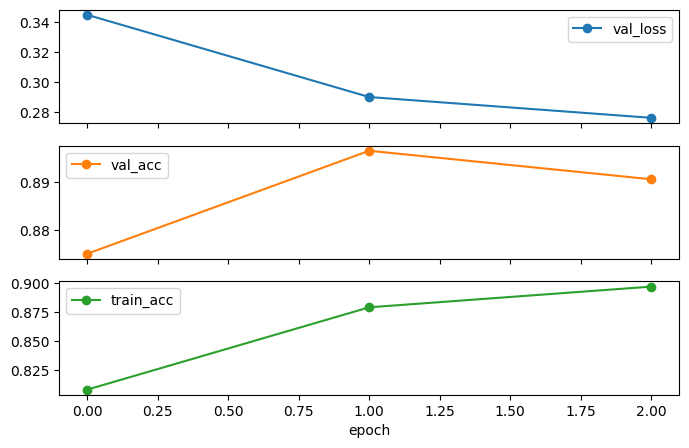

In [43]:
import pandas as pd

metrics = pd.read_csv(f"{trainer.logger.log_dir}/metrics.csv")
per_epoch = metrics.groupby("epoch")[["val_loss", "val_acc", "train_acc"]].mean().dropna() # z dropna uwagi na "epokę 3", która jest testowaniem
print(per_epoch)
per_epoch.plot(subplots=True, figsize=(8, 5), marker="o");

Wczytanie modelu z checkpointu i predykcja. Dzięki `save_hyperparameters()` `load_from_checkpoint` sam odtworzy `lr` i `num_classes`;
podajemy tylko sieć, której celowo nie zapisaliśmy w hiperparametrach. `trainer.predict` zwraca listę wyników `predict_step` – po jednym na batch:

In [44]:
best = LitClassifier.load_from_checkpoint(checkpoint.best_model_path, net=CNN())
predictions = torch.cat(trainer.predict(best, datamodule=dm))
targets = dm.test_set.targets
print("hparams:", dict(best.hparams), "| accuracy z predict:", (predictions == targets).float().mean().item())

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

hparams: {'lr': 0.001, 'num_classes': 10} | accuracy z predict: 0.8896999955177307


### Przydatne flagi `Trainer`

| flaga | co robi |
|---|---|
| `accelerator="auto"`, `devices=...` | wybór sprzętu; ten sam kod na CPU, GPU i wielu GPU (`strategy="ddp"`) |
| `precision="16-mixed"` / `"bf16-mixed"` | trening w mieszanej precyzji (AMP) |
| `gradient_clip_val=1.0` | przycinanie normy gradientu |
| `accumulate_grad_batches=4` | akumulacja gradientów – efektywnie 4× większy batch przy tej samej pamięci GPU |
| `fast_dev_run=True` | jeden batch train + val: test potoku |
| `overfit_batches=1` | trening na jednym batchu – czy model w ogóle potrafi się uczyć? |
| `limit_train_batches=0.1` | tylko 10% danych treningowych w epoce (szybkie próby) |
| `deterministic=True` | deterministyczne algorytmy PyTorch (razem z `seed_everything`) |
| `callbacks=[LearningRateMonitor()]` | logowanie aktualnego learning rate |

Do tego `Tuner(trainer).lr_find(...)` – automatyczne szukanie learning rate. Pełna lista: [dokumentacja `Trainer`](https://lightning.ai/docs/pytorch/stable/common/trainer.html).

# 2. Weights & Biases

Plik CSV albo TensorBoard wystarczą dla jednego eksperymentu na jednym komputerze. Gdy runów są dziesiątki (różne modele, learning rate, dane)
i pracuje nad nimi kilka osób, potrzebujemy narzędzia do **śledzenia eksperymentów**: wspólne wykresy, konfiguracja każdego runu, porównania,
przechowywanie modeli i danych (*artefakty*). [Weights & Biases](https://wandb.ai) to jedno z takich narzędzi; inne to m.in.
[MLflow](https://mlflow.org/), [Neptune](https://neptune.ai/), [ModelDB](https://github.com/VertaAI/modeldb).

**Klucz API.** Po założeniu konta klucz jest na https://wandb.ai/authorize. **Nigdy nie wpisujemy go do notatnika** – każdy, kto dostanie notatnik,
mógłby logować się na nasze konto. W Colab: ikona 🔑 (*Secrets*) w lewym pasku → *Add new secret* → nazwa `WANDB_API_KEY`, włączony *Notebook access*.
Bez klucza poniższa komórka przełączy W&B w tryb **offline** – wszystko działa, a wyniki trafiają tylko do lokalnego katalogu `wandb/`.

In [45]:
try:
    from google.colab import userdata
    key = userdata.get("WANDB_API_KEY")
except Exception:                       # poza Colab albo brak sekretu
    key = os.environ.get("WANDB_API_KEY")

if key:
    wandb.login(key=key)
else:
    os.environ["WANDB_MODE"] = "offline"
    print("Brak klucza W&B – tryb offline (wyniki tylko lokalnie, w katalogu wandb/)")

wandb: WARNING Unable to verify login in offline mode.


Z Lightningiem W&B to **jeden argument**: `logger=WandbLogger(...)` zamiast `CSVLogger`. Wszystko, co logujemy przez `self.log`, trafia na wykresy,
a hiperparametry z `save_hyperparameters()` – do konfiguracji runu (zakładka *Overview*; po nich filtrujemy i grupujemy runy).

Poza liczbami można logować obrazki, tabele, histogramy. Poniższy callback po każdej walidacji wysyła 16 obrazków z predykcją i prawdziwą klasą –
w W&B widać, **na czym** model się myli, a nie tylko **ile** razy:

In [46]:
class LogPredictions(Callback):
    def __init__(self, batch, classes, n=16):
        self.x, self.y, self.classes = batch[0][:n], batch[1][:n], classes

    def on_validation_epoch_end(self, trainer, pl_module):
        if trainer.sanity_checking or not isinstance(trainer.logger, WandbLogger):
            return
        with torch.no_grad():
            preds = pl_module(self.x.to(pl_module.device)).argmax(dim=1).cpu()
        images = [(x[0] * 0.3530 + 0.2860).clamp(0, 1).numpy() for x in self.x]   # odwrócenie normalizacji
        captions = [f"pred: {self.classes[p]} | true: {self.classes[t]}" for p, t in zip(preds, self.y)]
        trainer.logger.log_image(key="predictions", images=images, caption=captions)

Główna wartość W&B to **porównywanie runów**. Wytrenujmy dwa modele – CNN i MLP – i zobaczmy je na wspólnych wykresach w projekcie `gsn-lightning`.
Każdy run kończymy `wandb.finish()`, inaczej kolejny `WandbLogger` dopisywałby do tego samego runu:

In [47]:
val_batch = next(iter(dm.val_dataloader()))

for name, net in [("cnn", CNN()), ("mlp", MLP())]:
    L.seed_everything(42)
    wandb_logger = WandbLogger(project="gsn-lightning", name=name, log_model=False)
    trainer = L.Trainer(
        max_epochs=3, accelerator="auto",
        precision="16-mixed" if torch.cuda.is_available() else "32-true",
        logger=wandb_logger,
        callbacks=[ModelCheckpoint(monitor="val_loss", mode="min"), LogPredictions(val_batch, dm.classes)],
    )
    trainer.fit(LitClassifier(net, lr=1e-3), datamodule=dm)
    trainer.test(datamodule=dm, ckpt_path="best")
    wandb.finish()

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


wandb: WARNING `resume` will be ignored since W&B syncing is set to `offline`. Starting a new run with run id 8unno0e0.


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net       │ CNN                │  421 K │ train │     0 │
│ 1 │ train_acc │ MulticlassAccuracy │      0 │ train │     0 │
│ 2 │ val_acc   │ MulticlassAccuracy │      0 │ train │     0 │
│ 3 │ test_acc  │ MulticlassAccuracy │      0 │ train │     0 │
└───┴───────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 421 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 421 K                                                                                                
Total estimated model params size (MB): 1.687                                                                      
Modules in train mode: 17                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

... (14 outputs left out)

INFO: Restoring states from the checkpoint path at ./gsn-lightning/8n450941/checkpoints/epoch=1-step=782.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at ./gsn-lightning/8n450941/checkpoints/epoch=1-step=782.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at ./gsn-lightning/8n450941/checkpoints/epoch=1-step=782.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at ./gsn-lightning/8n450941/checkpoints/epoch=1-step=782.ckpt


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.8623999953269958     │
│         test_loss         │    0.3828863203525543     │
└───────────────────────────┴───────────────────────────┘

epoch,▁▁▁▁▁▁▁▁▁▃▃▃▃▃▃▃▃▃▃▆▆▆▆▆▆▆▆▆▆█
test_acc,▁
test_loss,▁
train_acc,▁▆█
train_loss,▆▅▅▆▄▆▂▃█▂▁▆▃▃▂▃▂▂▁▃▁▂▂
trainer/global_step,▁▁▂▂▂▃▃▃▃▃▃▃▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇██████
val_acc,▁██
val_loss,█▁▃
epoch,3
test_acc,0.8624
test_loss,0.38289


Na co patrzeć w panelu W&B (link do projektu jest w outpucie powyżej):
- **Workspace** – `val_acc`, `val_loss` obu runów na jednym wykresie; `train_loss` krok po kroku,
- **Media** – obrazki z callbacka: które klasy się mylą (koszula / T-shirt / pulower),
- **Overview** i **tabela runów** – hiperparametry (`lr`, `num_classes`, `batch_size`…) i wynik `test_acc`; sortowanie, filtrowanie, grupowanie,
- **System** – wykorzystanie GPU i pamięci.

W trybie offline runy można wysłać później: `wandb sync wandb/offline-run-*`.

**Artefakty.** `WandbLogger(log_model=...)` może sam wysyłać checkpointy z `ModelCheckpoint` jako wersjonowany artefakt typu `model`:
`True` – po zakończeniu treningu, `"all"` – każdy checkpoint od razu (odporne na przerwany trening, ale zajmuje więcej miejsca).
Najlepsza wersja dostaje alias `best`, a pobiera się ją np. `wandb.Api().artifact("<projekt>/model-<id runu>:best").download()`.

# 3. Hydra

Skrypty treningowe szybko obrastają w argumenty – np. [skrypt do trenowania na ImageNet z przykładów PyTorch](https://github.com/pytorch/examples/blob/main/imagenet/main.py)
ma ich kilkadziesiąt. Naturalny następny krok to pliki konfiguracyjne, ale wtedy przybywa plików, które w 90% są identyczne.
[Hydra](https://hydra.cc/) (autor: Omry Yadan) proponuje, by konfigurację **składać** jak kod:

- konfiguracja to drzewo YAML złożone z małych plików (np. osobno dane, model, logger),
- każdą wartość i każdy „klocek” można nadpisać z linii poleceń, bez zmiany kodu,
- obiekty (model, dane, logger…) tworzy się wprost z konfiguracji (`instantiate`),
- każde uruchomienie dostaje własny katalog wyników z zapisaną pełną konfiguracją – łatwo odtworzyć eksperyment.

## OmegaConf: konfiguracja jako obiekt

Hydra korzysta z biblioteki OmegaConf. Konfiguracja to `DictConfig` – działa jak słownik, ale z dostępem przez kropkę i z **interpolacją** `${...}`:

In [48]:
from omegaconf import OmegaConf

cfg = OmegaConf.create({
    "data": {"batch_size": 128, "num_classes": 10},
    "model": {"hidden": 256, "num_classes": "${data.num_classes}"},   # wartość pobrana z innego miejsca drzewa
})
print(cfg.data.batch_size, cfg.model.num_classes)
print(OmegaConf.to_yaml(cfg, resolve=True))

128 10
data:
  batch_size: 128
  num_classes: 10
model:
  hidden: 256
  num_classes: 10



## `instantiate`: obiekty z konfiguracji

Klucz `_target_` to pełna ścieżka do klasy lub funkcji, pozostałe klucze – argumenty. Zagnieżdżone `_target_` są tworzone **rekurencyjnie**,
a `_partial_: true` daje funkcję z częścią argumentów (przydatne np. dla optymalizatora, który potrzebuje jeszcze `model.parameters()`):

In [49]:
from hydra.utils import instantiate

model_cfg = OmegaConf.create({
    "_target_": "gsn.lit_module.LitClassifier",
    "lr": 3e-3,
    "net": {"_target_": "gsn.models.MLP", "hidden": 64},      # zagnieżdżony obiekt
})
lit_model = instantiate(model_cfg)
print(type(lit_model).__name__, dict(lit_model.hparams), lit_model.net)

optimizer_factory = instantiate({"_target_": "torch.optim.SGD", "_partial_": True, "lr": 0.1, "momentum": 0.9})
print(optimizer_factory(lit_model.parameters()))

LitClassifier {'lr': 0.003, 'num_classes': 10} MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.1
    maximize: False
    momentum: 0.9
    nesterov: False
    weight_decay: 0
)


## Projekt z Hydrą

Te same pliki `gsn/*.py` uruchomimy teraz skryptem `main.py` sterowanym konfiguracją. Struktura:

```
├── main.py
├── conf
│   ├── config.yaml          # główna konfiguracja + lista domyślnych klocków (defaults)
│   ├── model
│   │   ├── cnn.yaml         # grupa "model": do wyboru cnn albo mlp
│   │   └── mlp.yaml
│   └── logger
│       ├── csv.yaml         # grupa "logger": csv albo wandb
│       └── wandb.yaml
└── gsn                      # kod z części o Lightning
```

W `defaults` wybieramy po jednym pliku z każdej **grupy**; `_self_` oznacza, że wartości z samego `config.yaml` są składane jako pierwsze,
a wybrane pliki mogą je nadpisać:

In [50]:
%%writefile conf/config.yaml
defaults:
  - _self_
  - model: cnn
  - logger: csv

seed: 42

data:
  _target_: gsn.data.FashionMNISTDataModule
  batch_size: 128
  num_workers: 2

trainer:
  max_epochs: 2
  accelerator: auto
  devices: 1
  precision: 32-true
  enable_progress_bar: false   # krótszy output w notatniku

Overwriting conf/config.yaml


In [51]:
from pathlib import Path

group_files = {
    "conf/model/cnn.yaml": """
_target_: gsn.lit_module.LitClassifier
lr: 1e-3
net:
  _target_: gsn.models.CNN
  dropout: 0.25
""",
    "conf/model/mlp.yaml": """
_target_: gsn.lit_module.LitClassifier
lr: 1e-3
net:
  _target_: gsn.models.MLP
  hidden: 256
""",
    "conf/logger/csv.yaml": """
_target_: lightning.pytorch.loggers.CSVLogger
name: csv
""",
    "conf/logger/wandb.yaml": """
_target_: lightning.pytorch.loggers.WandbLogger
project: gsn-hydra
name: ${hydra:runtime.choices.model}-lr${model.lr}   # nazwa runu z konfiguracji, np. cnn-lr0.001
""",
}
for path, text in group_files.items():
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(text.lstrip())
    print(f"===== {path}\n{text.strip()}\n")

===== conf/model/cnn.yaml
_target_: gsn.lit_module.LitClassifier
lr: 1e-3
net:
  _target_: gsn.models.CNN
  dropout: 0.25

===== conf/model/mlp.yaml
_target_: gsn.lit_module.LitClassifier
lr: 1e-3
net:
  _target_: gsn.models.MLP
  hidden: 256

===== conf/logger/csv.yaml
_target_: lightning.pytorch.loggers.CSVLogger
name: csv

===== conf/logger/wandb.yaml
_target_: lightning.pytorch.loggers.WandbLogger
project: gsn-hydra
name: ${hydra:runtime.choices.model}-lr${model.lr}   # nazwa runu z konfiguracji, np. cnn-lr0.001



`main.py` nie zawiera żadnej konkretnej wartości – wszystko pochodzi z konfiguracji. `@hydra.main` wczytuje i składa konfigurację,
uwzględnia nadpisania z linii poleceń i przekazuje gotowe drzewo jako `cfg`:

In [52]:
%%writefile main.py
import hydra
import lightning as L
import wandb
from hydra.core.hydra_config import HydraConfig
from hydra.utils import instantiate
from lightning.pytorch.callbacks import ModelCheckpoint
from omegaconf import DictConfig, OmegaConf


@hydra.main(version_base=None, config_path="conf", config_name="config")
def main(cfg: DictConfig) -> float:
    print(OmegaConf.to_yaml(cfg))
    out_dir = HydraConfig.get().runtime.output_dir          # osobny katalog wyników tego uruchomienia
    L.seed_everything(cfg.seed)

    dm = instantiate(cfg.data)
    model = instantiate(cfg.model)                          # LitClassifier + zagnieżdżona sieć (net)
    logger = instantiate(cfg.logger, save_dir=out_dir)      # dodatkowe argumenty uzupełniają konfigurację
    logger.log_hyperparams(OmegaConf.to_container(cfg, resolve=True))   # cała konfiguracja Hydry -> logger (np. W&B)

    checkpoint = ModelCheckpoint(dirpath=f"{out_dir}/checkpoints", monitor="val_loss", mode="min")
    trainer = L.Trainer(**cfg.trainer, logger=logger, callbacks=[checkpoint])   # cała sekcja trainer -> Trainer
    trainer.fit(model, datamodule=dm)
    test_acc = trainer.test(datamodule=dm, ckpt_path="best")[0]["test_acc"]

    if wandb.run is not None:                               # przy --multirun kolejne zadania muszą dostać nowy run
        wandb.finish()
    return test_acc


if __name__ == "__main__":
    main()

Overwriting main.py


Uruchomienie z konfiguracją domyślną (`model=cnn`, `logger=csv`):

In [53]:
!python main.py

seed: 42
data:
  _target_: gsn.data.FashionMNISTDataModule
  batch_size: 128
  num_workers: 2
trainer:
  max_epochs: 2
  accelerator: auto
  devices: 1
  precision: 32-true
  enable_progress_bar: false
model:
  _target_: gsn.lit_module.LitClassifier
  lr: 0.001
  net:
    _target_: gsn.models.CNN
    dropout: 0.25
logger:
  _target_: lightning.pytorch.loggers.CSVLogger
  name: csv

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net       │ CNN                │  421 K │ train │ 

### Nadpisywanie konfiguracji z linii poleceń

| składnia | znaczenie |
|---|---|
| `model.lr=3e-3` | zmiana wartości |
| `model=mlp` | wybór innego pliku z grupy `model` |
| `trainer.precision=16-mixed` | dowolna flaga `Trainer` – bo cała sekcja `trainer` trafia do `L.Trainer(**cfg.trainer)` |
| `+trainer.gradient_clip_val=1.0` | **dodanie** klucza, którego nie ma w konfiguracji (`+`) |
| `--multirun model=cnn,mlp` | osobne uruchomienie dla każdej kombinacji wartości |

In [54]:
!python main.py model=mlp model.lr=3e-3 trainer.max_epochs=1

seed: 42
data:
  _target_: gsn.data.FashionMNISTDataModule
  batch_size: 128
  num_workers: 2
trainer:
  max_epochs: 1
  accelerator: auto
  devices: 1
  precision: 32-true
  enable_progress_bar: false
model:
  _target_: gsn.lit_module.LitClassifier
  lr: 0.003
  net:
    _target_: gsn.models.MLP
    hidden: 256
logger:
  _target_: lightning.pytorch.loggers.CSVLogger
  name: csv

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net       │ MLP                │  203 K │ train │   

Hydra + W&B: `--multirun` uruchamia oba modele po kolei, a każdy trafia jako osobny run do projektu `gsn-hydra`,
z pełną konfiguracją Hydry w zakładce *Overview* i nazwą złożoną z konfiguracji:

In [55]:
!python main.py --multirun model=cnn,mlp logger=wandb trainer.max_epochs=1

[2026-11-23 09:05:28,116][HYDRA] Launching 2 jobs locally
[2026-11-23 09:05:28,116][HYDRA] 	#0 : model=cnn logger=wandb trainer.max_epochs=1
seed: 42
data:
  _target_: gsn.data.FashionMNISTDataModule
  batch_size: 128
  num_workers: 2
trainer:
  max_epochs: 1
  accelerator: auto
  devices: 1
  precision: 32-true
  enable_progress_bar: false
model:
  _target_: gsn.lit_module.LitClassifier
  lr: 0.001
  net:
    _target_: gsn.models.CNN
    dropout: 0.25
logger:
  _target_: lightning.pytorch.loggers.WandbLogger
  project: gsn-hydra
  name: ${hydra:runtime.choices.model}-lr${model.lr}

Seed set to 42
wandb: WARNING The anonymous setting has no effect and will be removed in a future version.
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: alexdad063 (alexdad063-politechnika-warszawska) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: Using an existing wandb-core service via WANDB_SERVICE.
wand

### Katalogi wyników

Każde uruchomienie ma własny katalog: `outputs/<data>/<godzina>/`, a przy `--multirun` – `multirun/<data>/<godzina>/<numer zadania>/`.
W podkatalogu `.hydra` Hydra zapisuje:
- `config.yaml` – pełna, złożona konfiguracja tego uruchomienia,
- `overrides.yaml` – nadpisania podane w linii poleceń,
- `hydra.yaml` – konfiguracja samej Hydry.

Od Hydry 1.2 (`version_base=None`) katalog roboczy się **nie zmienia** – dlatego `main.py` zapisuje logi i checkpointy jawnie do `output_dir`.

In [56]:
from pathlib import Path

last_job = sorted(Path("multirun").glob("*/*/*/.hydra"))[-1].parent
print(last_job)
for f in sorted(last_job.rglob("*")):
    if f.is_file() and "wandb" not in f.parts:   # pomijamy wewnętrzne pliki W&B
        print("  ", f.relative_to(last_job))
print("\noverrides.yaml:\n" + (last_job / ".hydra" / "overrides.yaml").read_text())

multirun/2026-11-23/09-05-27/1
   .hydra/config.yaml
   .hydra/hydra.yaml
   .hydra/overrides.yaml
   checkpoints/epoch=0-step=391.ckpt
   main.log

overrides.yaml:
- model=mlp
- logger=wandb
- trainer.max_epochs=1



### Konfiguracja w notatniku: Compose API

`@hydra.main` jest dla skryptów. W notatniku (albo w testach) tę samą konfigurację, z tymi samymi nadpisaniami, składa `compose`:

In [57]:
import os
from hydra import compose, initialize_config_dir
from omegaconf import OmegaConf
from hydra.utils import instantiate

# Pobieramy pełną ścieżkę bezwzględną do folderu 'conf' w środowisku Colab
abs_config_dir = os.path.abspath("conf")

# Używamy initialize_config_dir, które pozwala na podanie absolutnej ścieżki
with initialize_config_dir(version_base=None, config_dir=abs_config_dir):
    cfg = compose(config_name="config", overrides=["model=mlp", "model.net.hidden=128"])

print(OmegaConf.to_yaml(cfg.model))
print(instantiate(cfg.model).net)

_target_: gsn.lit_module.LitClassifier
lr: 0.001
net:
  _target_: gsn.models.MLP
  hidden: 128

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


### Przeszukiwanie hiperparametrów

- **siatka** – wbudowana: `python main.py --multirun model=cnn,mlp model.lr=1e-4,1e-3` (4 uruchomienia),
- **optymalizacja bayesowska** – plugin `hydra-optuna-sweeper`: Optuna minimalizuje lub maksymalizuje **wartość zwracaną** z `main` (u nas `test_acc`;
  w praktyce raczej metryka walidacyjna):
  `python main.py --multirun hydra/sweeper=optuna hydra.sweeper.n_trials=10 hydra.sweeper.direction=maximize 'model.lr=interval(1e-4,1e-2)'`,
- **W&B Sweeps** (`wandb.sweep` + `wandb.agent`) – przeszukiwanie sterowane z W&B, z wykresami zależności wyniku od hiperparametrów.

# Podsumowanie

| | odpowiada za | w naszym kodzie |
|---|---|---|
| **Lightning** | strukturę kodu i pętlę treningową | `FashionMNISTDataModule`, `LitClassifier`, `L.Trainer(...)` |
| **W&B** | śledzenie i porównywanie eksperymentów | `WandbLogger`, `self.log`, `save_hyperparameters`, `log_image` |
| **Hydra** | konfigurację i uruchamianie eksperymentów | `conf/*.yaml`, `instantiate`, nadpisania, `--multirun`, katalogi wyników |

Gotowy szablon projektu łączącego te trzy narzędzia: [lightning-hydra-template](https://github.com/ashleve/lightning-hydra-template).
Dokumentacja: [Lightning](https://lightning.ai/docs/pytorch/stable/), [W&B](https://docs.wandb.ai/), [Hydra](https://hydra.cc/docs/intro/).